In [11]:
import tensorflow as tf
import keras
from keras.applications.vgg16 import VGG16, preprocess_input

In [3]:
model = VGG16()
model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
for i in range((len(model.layers))):
    if 'conv' not in model.layers[i].name:
        continue
    filter, bias = model.layers[i].get_weights()
    print(f"Layer {i} : {model.layers[i].name} {filter.shape}")

Layer 1 : block1_conv1 (3, 3, 3, 64)
Layer 2 : block1_conv2 (3, 3, 64, 64)
Layer 4 : block2_conv1 (3, 3, 64, 128)
Layer 5 : block2_conv2 (3, 3, 128, 128)
Layer 7 : block3_conv1 (3, 3, 128, 256)
Layer 8 : block3_conv2 (3, 3, 256, 256)
Layer 9 : block3_conv3 (3, 3, 256, 256)
Layer 11 : block4_conv1 (3, 3, 256, 512)
Layer 12 : block4_conv2 (3, 3, 512, 512)
Layer 13 : block4_conv3 (3, 3, 512, 512)
Layer 15 : block5_conv1 (3, 3, 512, 512)
Layer 16 : block5_conv2 (3, 3, 512, 512)
Layer 17 : block5_conv3 (3, 3, 512, 512)


# Retrieving the weights of the Second Hidden Layer

In [7]:
filters, bias = model.layers[1].get_weights()

In [8]:
# Normalizing the Weights 
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

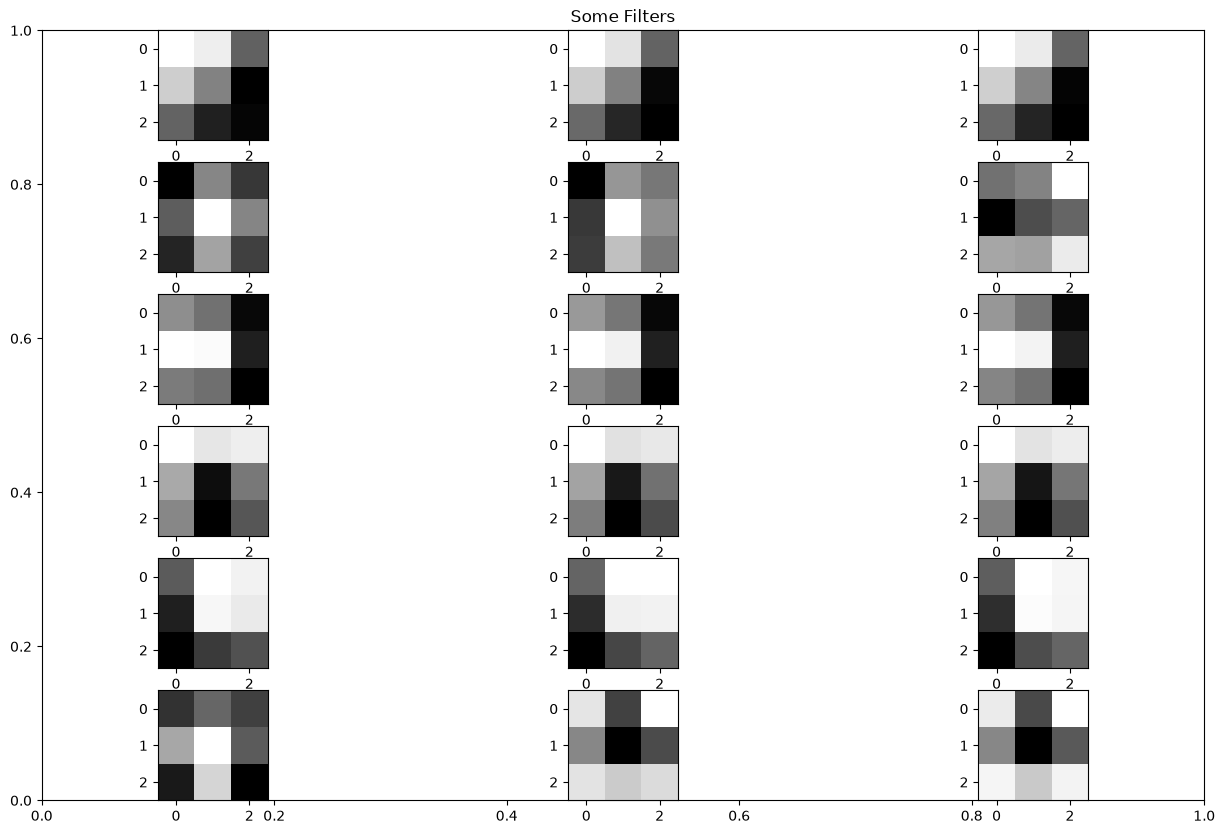

In [ ]:
import matplotlib.pyplot as plt

n_filters = 6
ix = 1
fig = plt.figure(figsize=(15, 10))
plt.title("Some Filters")
for i in range(n_filters):
    f = filters[:, :, :, i]
    for j in range(3):
        plt.subplot(n_filters, 3, ix)
        plt.imshow(f[:,:,j], cmap='gray')
        ix+=1

plt.show()

In [12]:
from keras import Model
model = Model(inputs = model.inputs, outputs = model.layers[1].output)

from keras.preprocessing import image

img = image.load_img("image.png", target_size=(224, 224))

img = image.img_to_array(img)

img = tf.expand_dims(img, axis = 0)

img = preprocess_input(img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 866ms/step


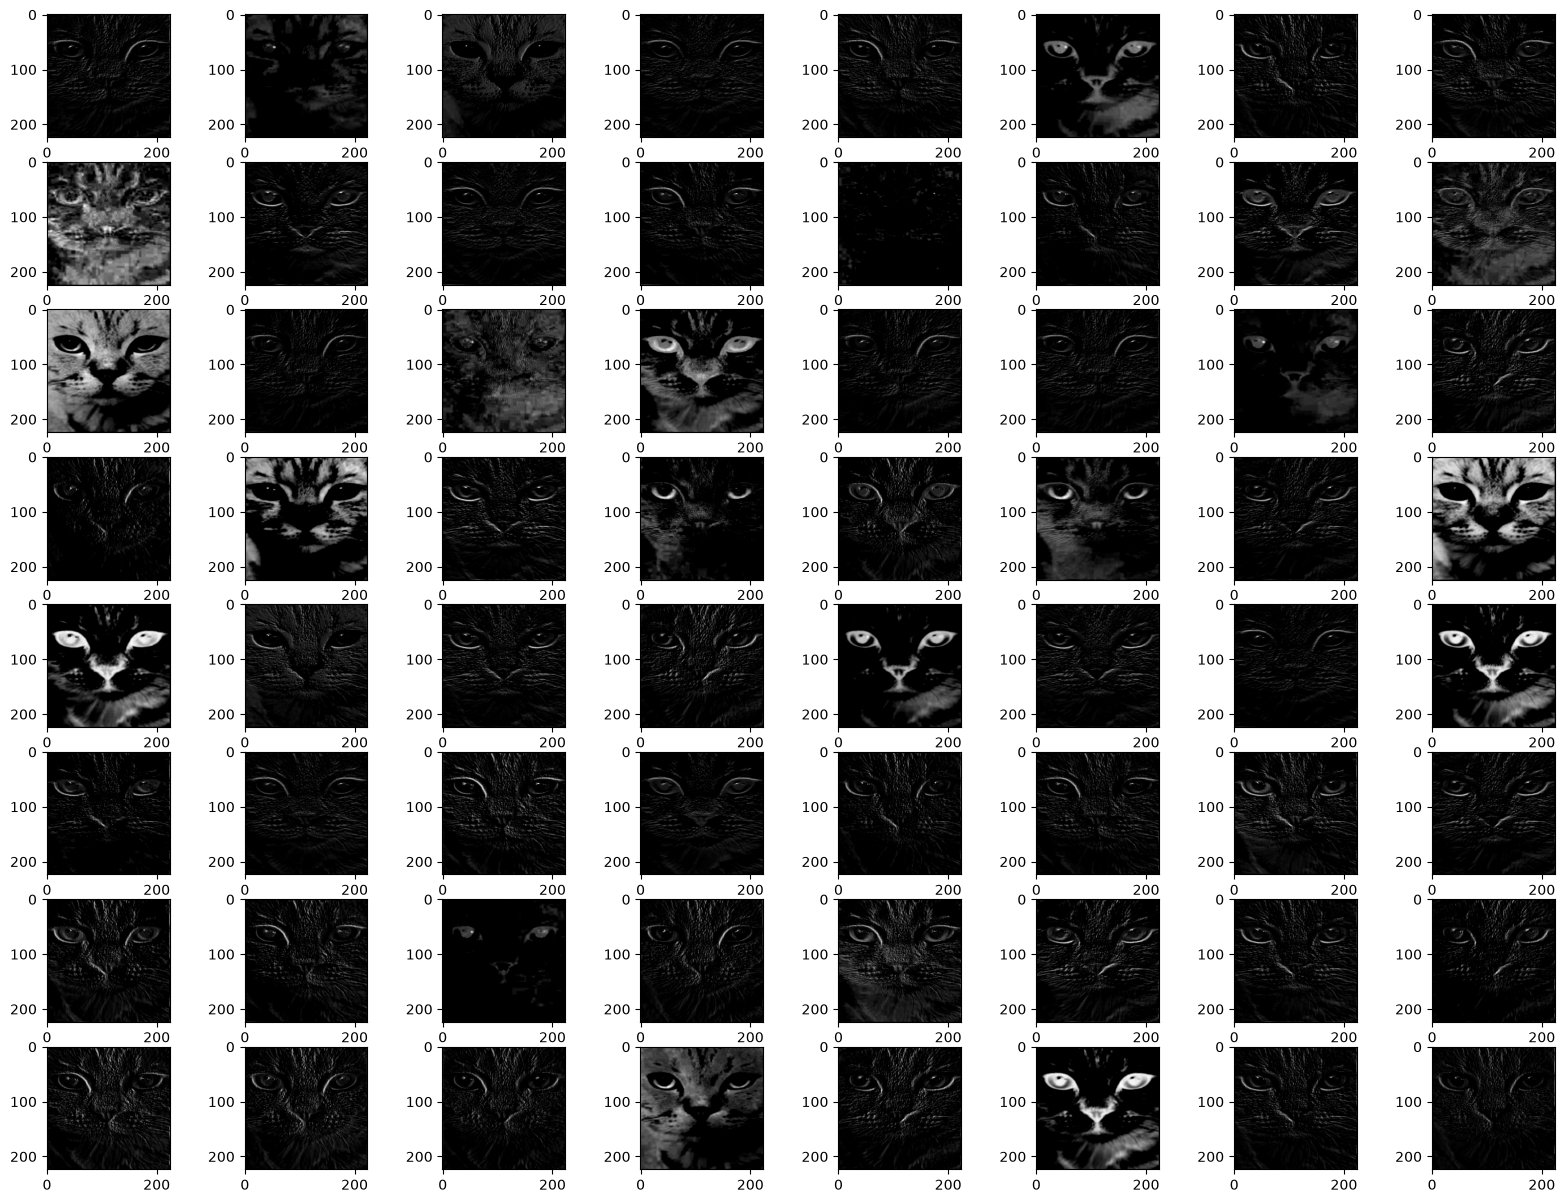

In [13]:
features = model.predict(img)

fig = plt.figure(figsize=(20, 15))
for i in range(1, features.shape[3] + 1):
    plt.subplot(8,8,i)
    plt.imshow(features[0,:,:,i-1], cmap = 'gray')
plt.show()

### Some of the feature Maps are showing the cat eyes & nose.

In [15]:
model2 = VGG16()

layer_index = [2,5,9,13,17]
outputs = [model2.layers[i].output for i in layer_index]

model3 = Model(inputs = model2.inputs, outputs = outputs)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 666ms/step


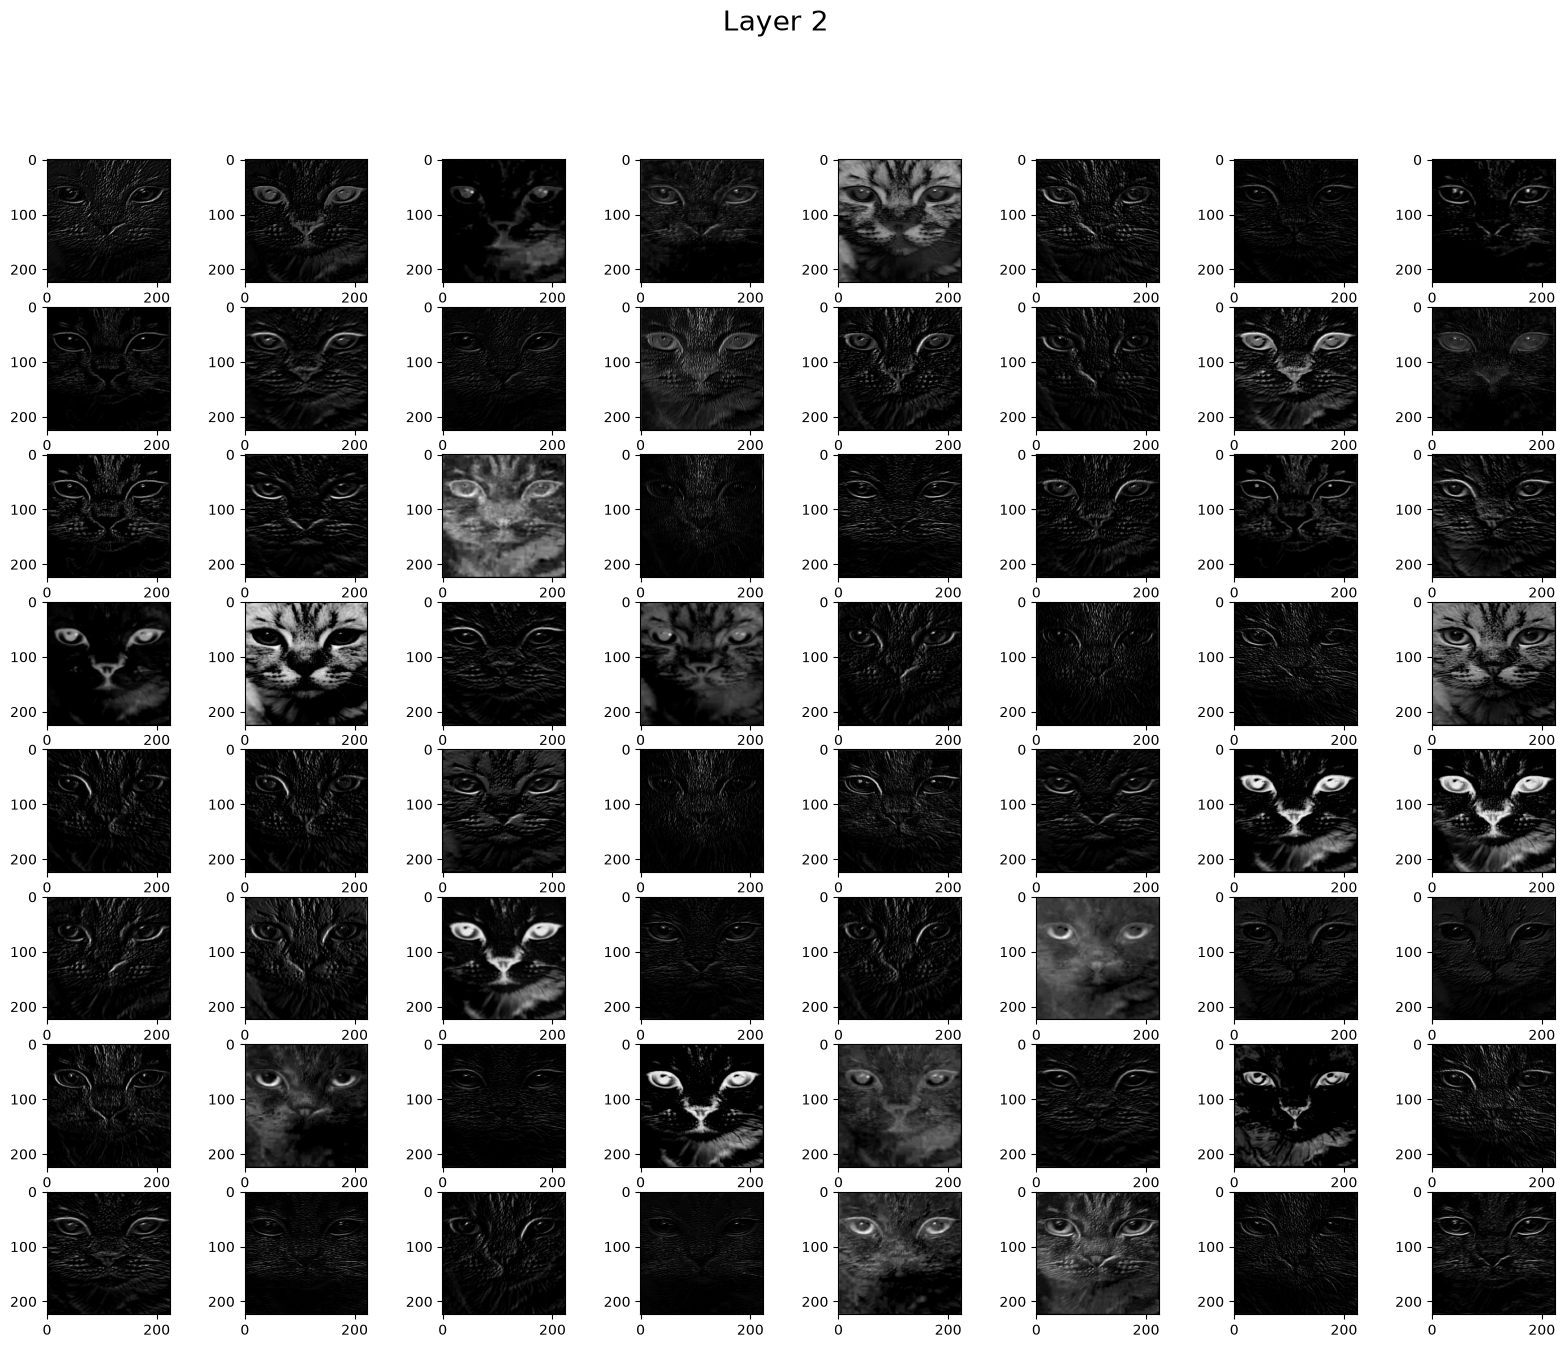

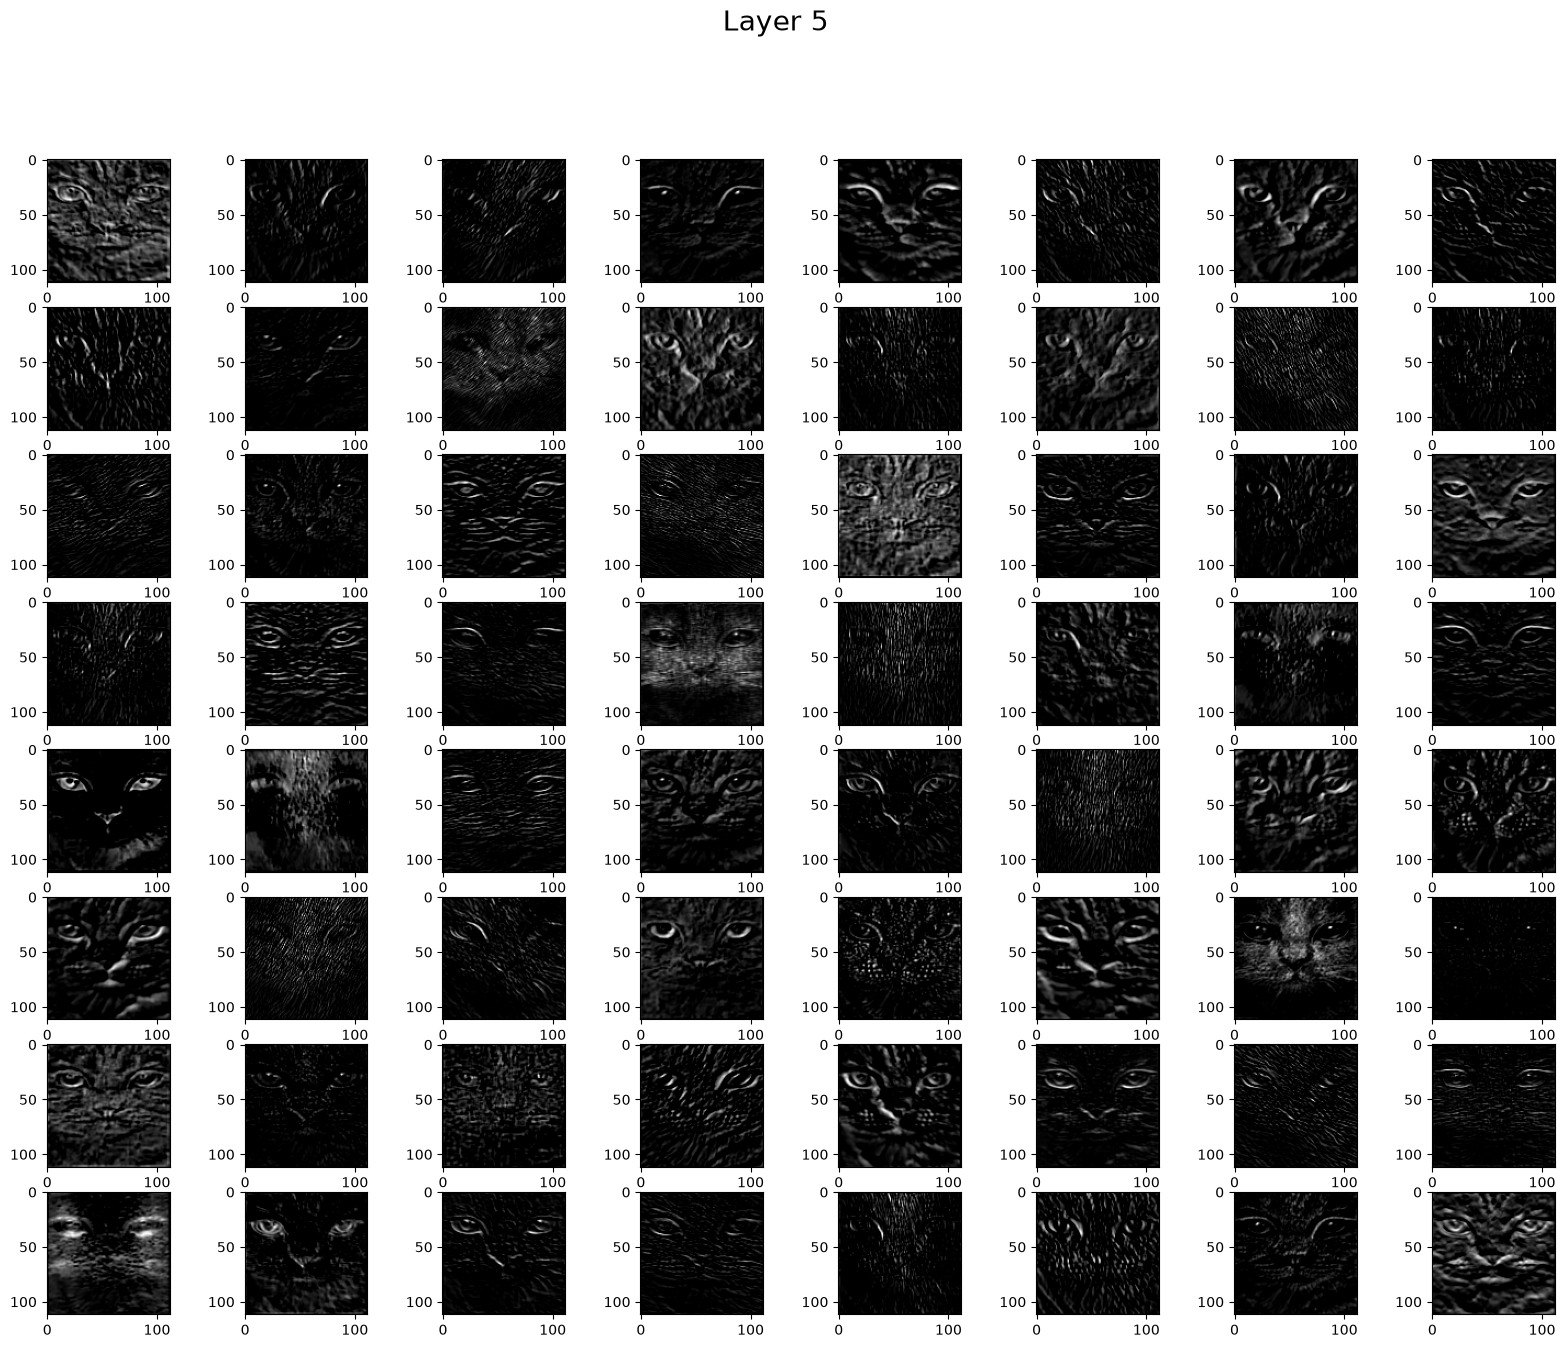

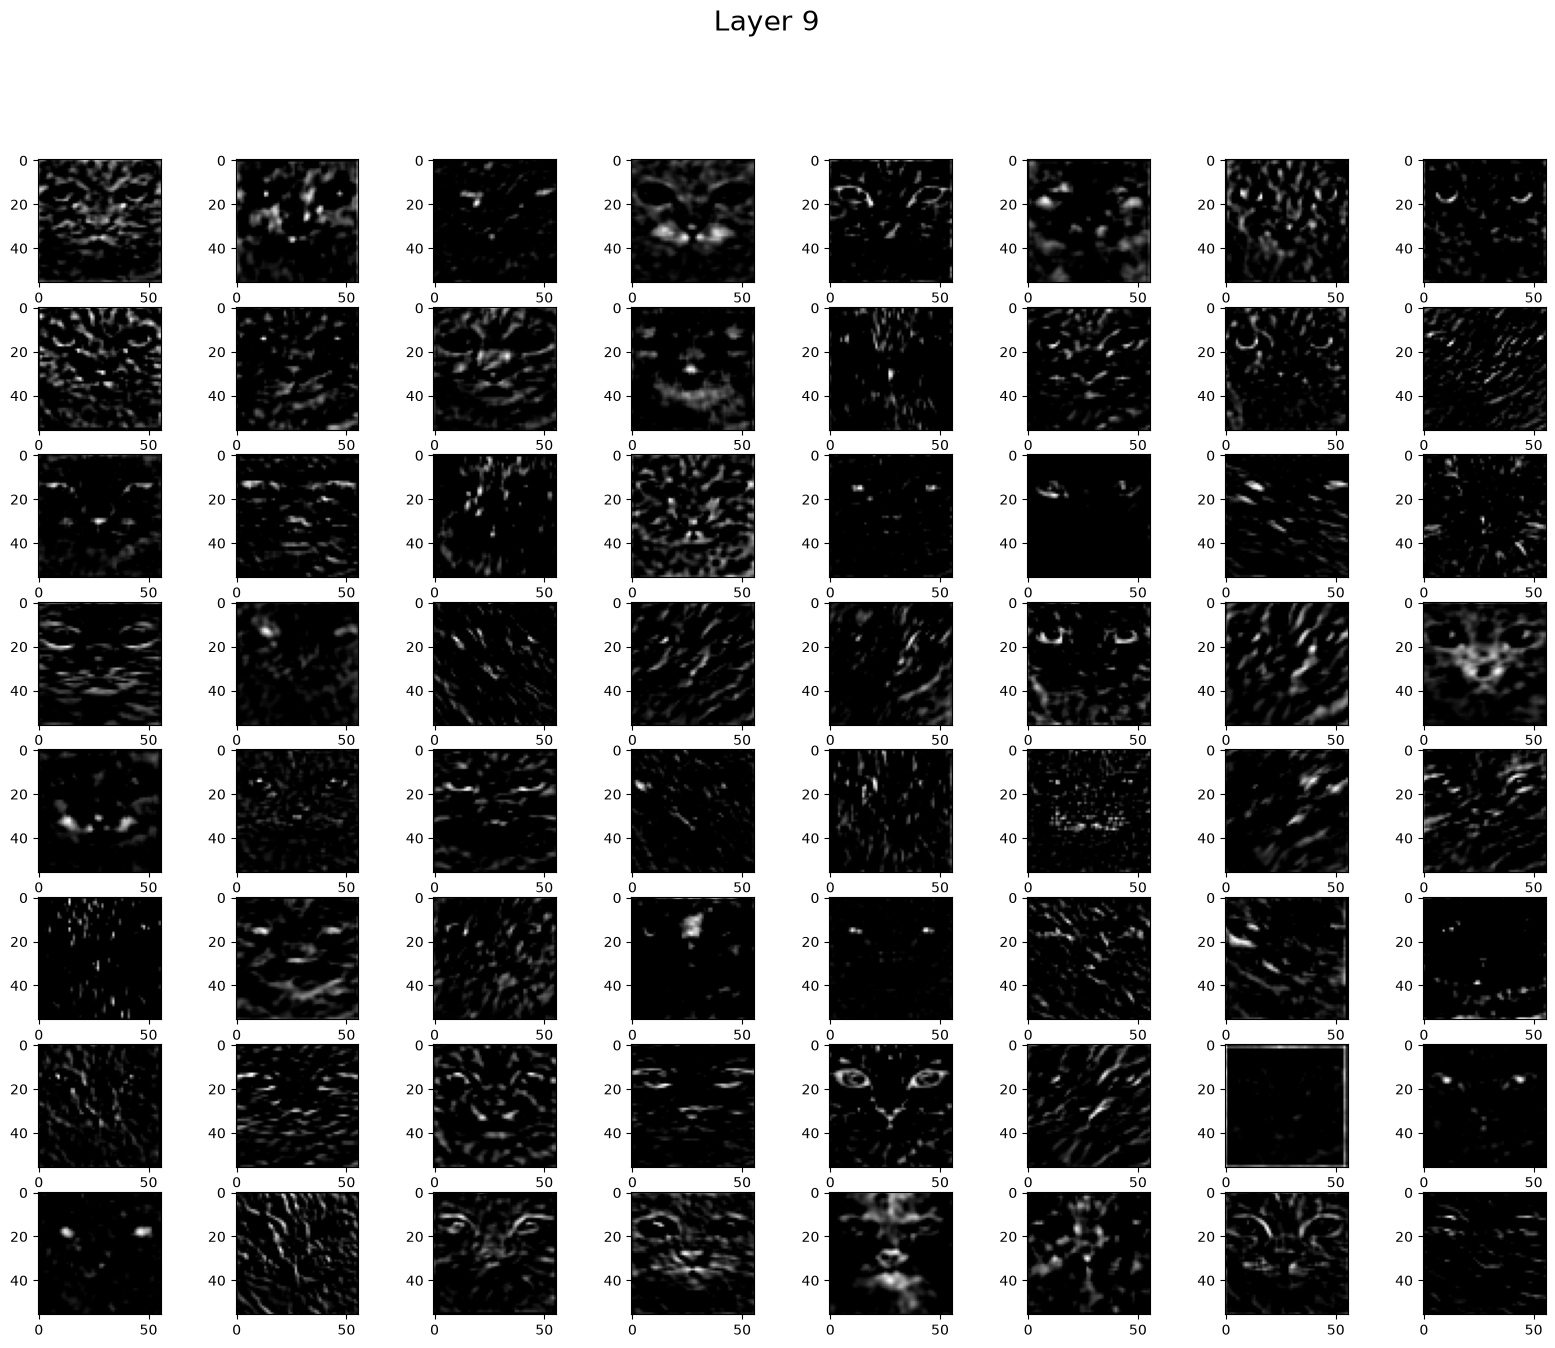

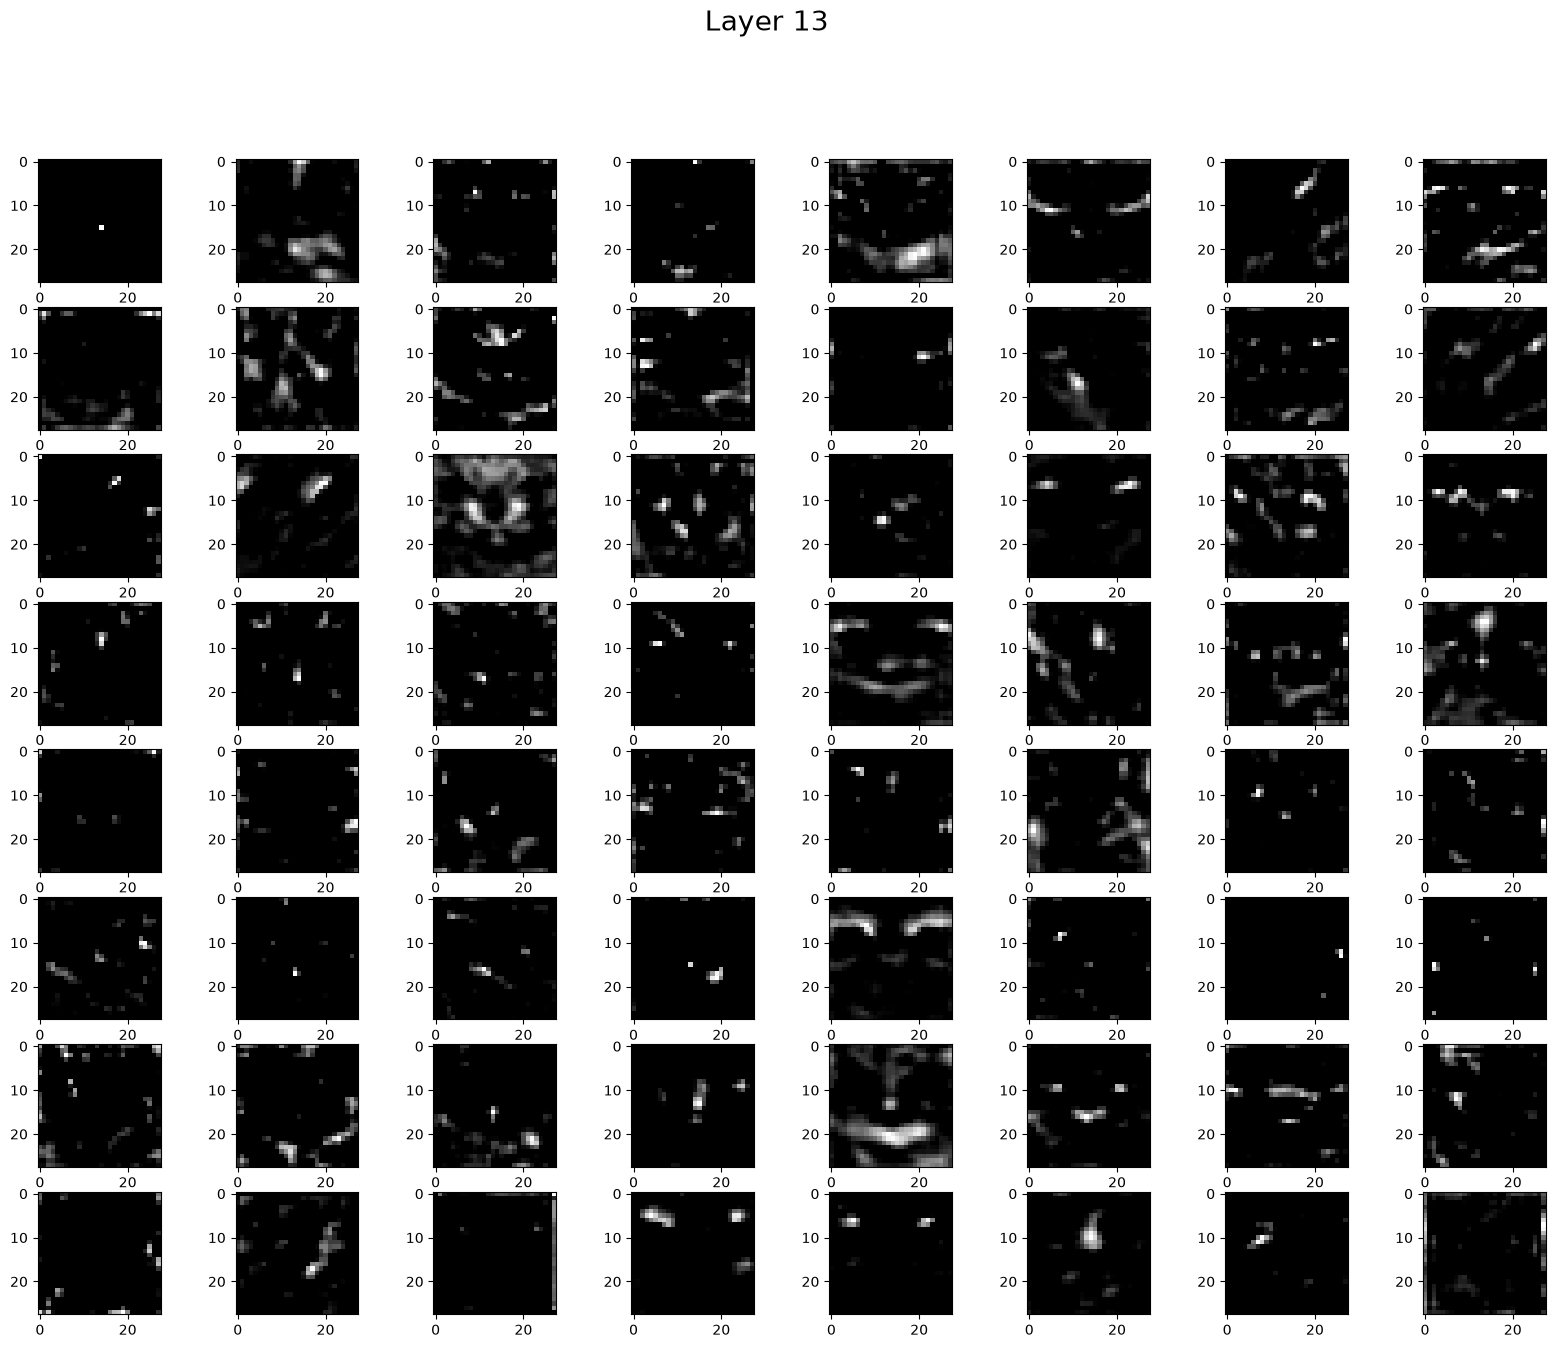

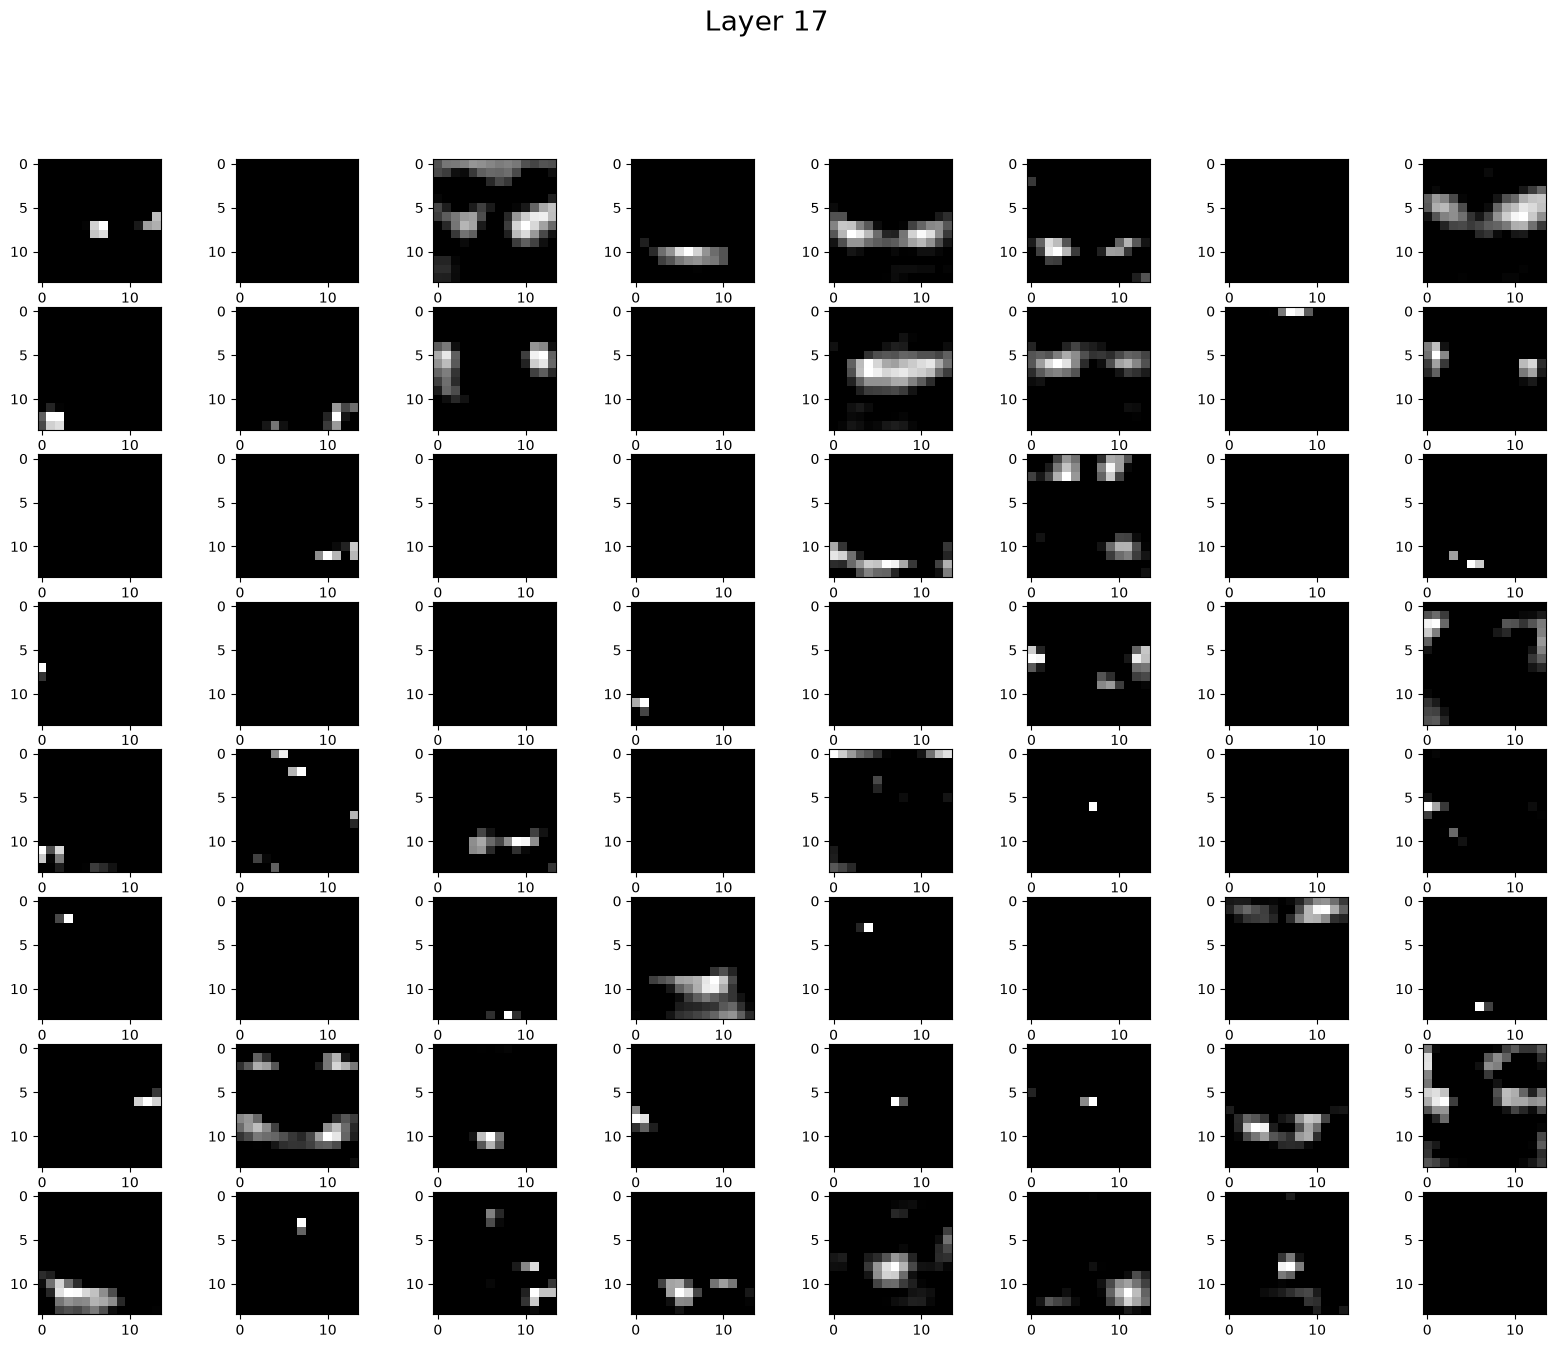

In [17]:
feature_maps = model3.predict(img)

for i, fmap in zip(layer_index, feature_maps):
    fig = plt.figure(figsize=(20, 15))
    fig.suptitle(f"Layer {i}", fontsize = 20)
    for j in range(1, features.shape[3]+1):
        plt.subplot(8,8,j)
        plt.imshow(fmap[0,:,:,j-1], cmap = 'gray')

plt.show()